# Projeto 3: classificação de spam
**Data Science 2 · ESEG · Prof. Marino Catarino**
**Autores:** Phelipe Torres Pamponet da França (RA 46643) e Felipe Marins (RA 44776)

Este notebook conta a história do projeto do começo ao fim, com o código principal visível. Ele roda em poucos
minutos (*Restart & Run All*): as partes pesadas (o torneio de 22 modelos, os milhares de treinos do algoritmo
genético, o TabPFN na nuvem) foram executadas nos notebooks técnicos `notebooks/01` a `09`, e os resultados
estão em `resultados/`. **Nenhum resultado foi digitado à mão no texto:** os números aparecem nas saídas das
células e vêm de `resultados/metricas_finais.json`. No texto ficam só nomes e parâmetros do projeto, como o custo 9:1.

**Termos.** *E-mail real* = e-mail legítimo (classe 0). *Spam* = classe 1. *Na lixeira* = e-mail real marcado
como spam (o erro caro). *Spam que passou* = spam que chegou à caixa de entrada.

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/Projeto3_Classificacao_Spam.ipynb)

**No Google Colab:** rode tudo (*Ambiente de execução → Executar tudo*). Na primeira vez, a célula abaixo baixa o
projeto, instala os pacotes e **reinicia o ambiente**; quando o Colab reconectar, use *Executar tudo* de novo.
No computador, ela não faz nada (siga o [INSTALACAO.md](https://github.com/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/INSTALACAO.md)).

In [1]:
# Google Colab: prepara o ambiente na primeira execução. No computador, esta célula não faz nada.
import os, subprocess, sys
if "google.colab" in sys.modules:
    PROJETO = "/content/filtro-spam-stacking-enron"
    if not os.path.isdir(PROJETO):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/felipe44776-eseg/filtro-spam-stacking-enron.git", PROJETO], check=True)
    os.chdir(PROJETO)
    sys.path.insert(0, PROJETO)
    MARCA = "/content/.spamfilter_instalado"
    if not os.path.exists(MARCA):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
        open(MARCA, "w").close()
        print("Pacotes instalados. O Colab vai reiniciar o ambiente: quando reconectar, use Executar tudo de novo.")
        os.kill(os.getpid(), 9)

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from spamfilter import caminhos, conversao, dados, estatistica, genetico, graficos, metricas, modelos, publicados
from spamfilter.motor import Motor

R = json.loads((caminhos.RESULTADOS / "metricas_finais.json").read_text(encoding="utf-8"))
F = R["finais"]
fig_ = lambda nome: display(Image(filename=str(caminhos.RESULTADOS / "figuras" / f"{nome}.png"), width=720))
pct = lambda x: f"{100 * x:.1f}%".replace(".", ",")
num = lambda x, c=3: f"{x:.{c}f}".replace(".", ",")
sn = lambda x, c=4: f"{x:+.{c}f}".replace(".", ",")          # com sinal: +0,0063

## 1. O problema e a base
Cada e-mail do CSV é descrito pela contagem das palavras de um vocabulário fixo. Descobrimos que o CSV é o
**Enron1** do corpus Enron-Spam (Metsis et al., 2006): e-mails reais da caixa de um funcionário da Enron e spams
de uma coleção de spam de outra época. E descobrimos **como** as palavras foram contadas: `texto.count(palavra)`,
como *substring*, diferenciando maiúsculas.

In [3]:
base = dados.carregar()
b = R["base"]
fonte = R["terceira_base"]["fontes_spam"][0]
print(f"{b['n_emails']} e-mails | {b['n_email_real']} reais | {b['n_spam']} spams | {b['n_palavras']} colunas | "
      f"{pct(b['fracao_zeros'])} das células são zero")
print(f"e-mails reais: caixa {fonte['email_real']}, de {fonte['email_real_de']} a {fonte['email_real_ate']} | "
      f"spams: coleção {fonte['spam']}, de {fonte['spam_de']} a {fonte['spam_ate']}")
print(f"linhas do CSV reproduzidas a partir dos textos originais: {b['linhas_reproduzidas']}/{b['n_emails']}")

# a mesma contagem, aplicada a um texto qualquer:
exemplo = "Subject: cheap meds online\nget your prescription drugs now , no doctor needed !"
v = conversao.vetor(conversao.para_aueb(exemplo), base.vocab)
print({w: int(v[i]) for i, w in enumerate(base.vocab) if v[i] and len(w) >= 3})

5172 e-mails | 3672 reais | 1500 spams | 3000 colunas | 94,4% das células são zero
e-mails reais: caixa farmer-d, de 1999-12-10 a 2002-01-11 | spams: coleção GP, de 2003-12-18 a 2005-09-06
linhas do CSV reproduzidas a partir dos textos originais: 5172/5172
{'ect': 1, 'you': 1, 'your': 1, 'our': 1, 'need': 1, 'get': 1, 'now': 1, 'line': 1, 'online': 1, 'needed': 1, 'doc': 1, 'prescription': 1, 'meds': 1, 'drugs': 1, 'oct': 1, 'cheap': 1, 'doctor': 1, 'pre': 1, 'drug': 1}


Um detalhe muda a leitura das colunas: como a contagem é por substring, o vocabulário tem letras soltas, e "ect"
aparece em todos os e-mails, porque está dentro de "subj**ect**".

colunas de uma letra só: 26 | e-mails com 'ect': 100,0%


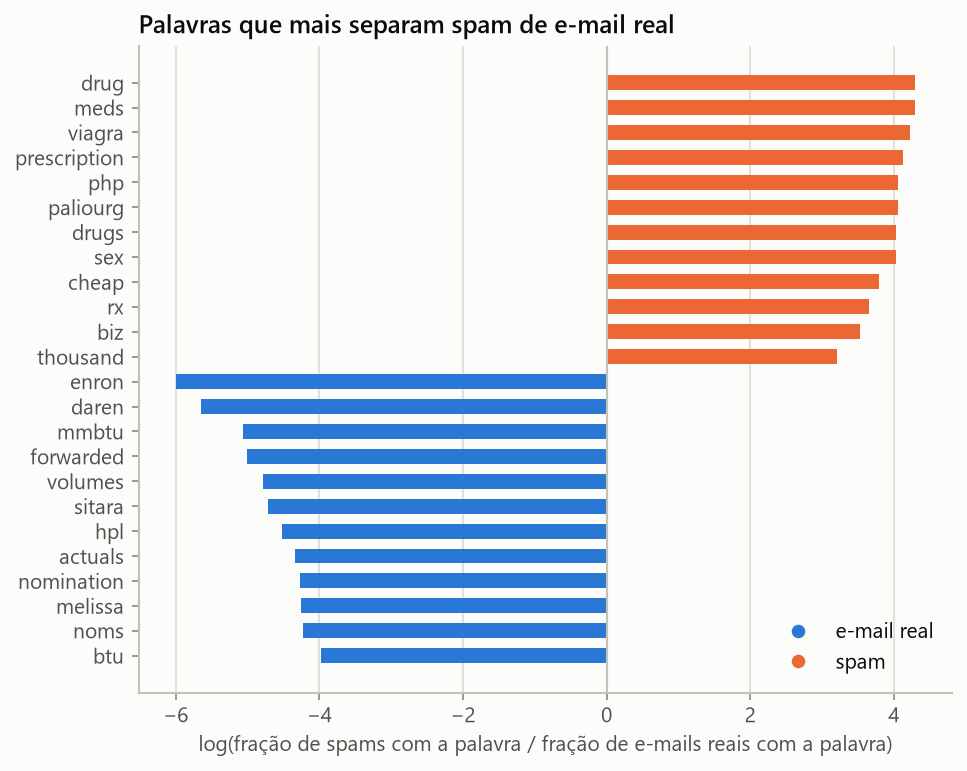

In [4]:
j_ect = list(base.vocab).index("ect")
print(f"colunas de uma letra só: {b['colunas_1_letra']} | e-mails com 'ect': {pct((base.X[:, j_ect] > 0).mean())}")
fig_("01_palavras_que_separam")

Uma palavra da figura não é vocabulário de spam: **paliourg** é o usuário de e-mail de G. Paliouras, um dos
pesquisadores que montaram a coleção de spam. Ela aparece nos spams por causa da coleta: é um artefato da base,
e o contra-estudo (seção 10) a retira junto com as palavras da Enron.

## 2. Qualidade dos dados: duplicata indica spam? Não.

In [5]:
d = dados.resumo_duplicatas(base)
print(f"cópias excedentes: {d['duplicatas_excedentes']}, das quais {pct(d['fracao_duplicatas_email_real'])} são e-mails reais "
      f"(avisos automáticos de modelo fixo)")
dev, teste = dados.indices_teste(base)
print(f"protocolo: cópias idênticas ficam sempre do mesmo lado (StratifiedGroupKFold por grupo). "
      f"Base de teste trancada: {len(teste)} e-mails, sorteada uma vez e guardada.")

cópias excedentes: 541, das quais 92,8% são e-mails reais (avisos automáticos de modelo fixo)


protocolo: cópias idênticas ficam sempre do mesmo lado (StratifiedGroupKFold por grupo). Base de teste trancada: 1035 e-mails, sorteada uma vez e guardada.


O agrupamento só junta cópias **idênticas**. Quase-cópias (o mesmo aviso com outra data) podem cair dos dois
lados da divisão; o efeito delas é medido no contra-estudo (seção 10).

## 3. Olhando sem rótulo (não supervisionado) e com meio rótulo (semissupervisionado)

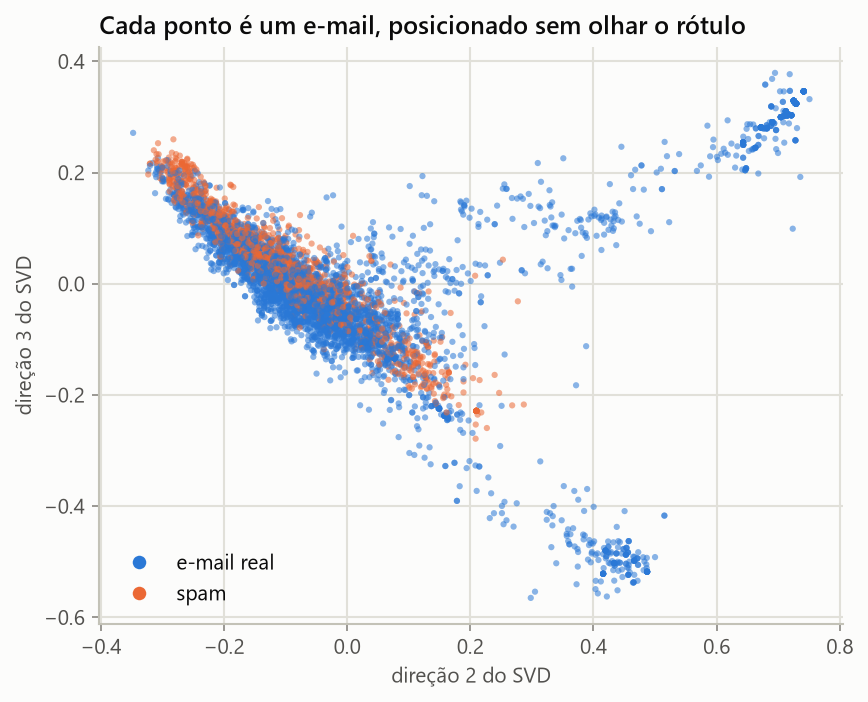

ARI (0 = acaso, 1 = coincide com spam × real): K-means -0,070 | hierárquico -0,071
tópico 4: 65,2% de spam | our, you, your, and, the, com
tópico 8: 4,2% de spam | enron, hou, corp, subject, ward, forwarded
tópico 5: 3,8% de spam | eastrans, deliver, deliveries, east, live, mmbtu
tópico 7: 3,3% de spam | calpine, alpine, nomination, daily, nat, min


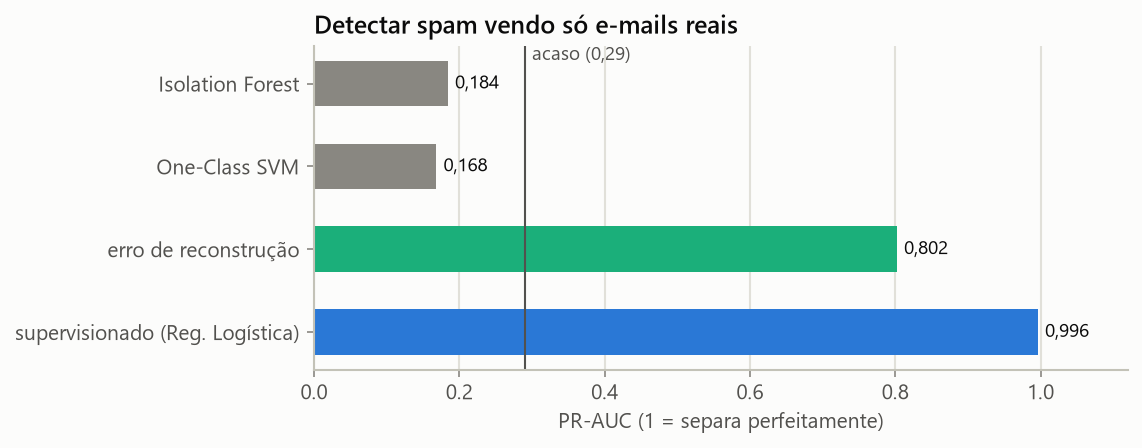

detecção de novidade (treina só com e-mails reais): erro de reconstrução, PR-AUC 0,802 (sortear daria 0,290)


In [6]:
ns = R["nao_supervisionado"]
fig_("02_svd_2d")
print(f"ARI (0 = acaso, 1 = coincide com spam × real): K-means {num(ns['kmeans_ari'])} | hierárquico {num(ns['hierarquico_ari'])}")
for t in ns["nmf_topicos"][:4]:
    print(f"tópico {t['topico']}: {pct(t['fracao_spam'])} de spam | {', '.join(t['palavras'][:6])}")
fig_("02_anomalia")
an = ns["anomalia_so_email_real"]
print(f"detecção de novidade (treina só com e-mails reais): erro de reconstrução, PR-AUC {num(an['reconstrucao_pr_auc'])} "
      f"(sortear daria {num(b['n_spam'] / b['n_emails'])})")

**K-means, agrupamento hierárquico e NMF não usam o rótulo:** os grupos que eles encontram são *assuntos*, não
"spam × real". A detecção de novidade é **semissupervisionada**: treina só com e-mails sabidamente reais, sem
nenhum spam rotulado. Os detectores clássicos (Isolation Forest, One-Class SVM) ficam abaixo do acaso; o erro de
reconstrução, que mede quanto do e-mail as direções dos e-mails reais não explicam, separa bem.

## 4. Como medir
Quem nunca marca spam já acerta a maioria (saída abaixo); por isso a acurácia engana. Usamos o **MCC** (−1 a 1;
0 = acaso), o **PR-AUC** (qualidade da ordenação, sem limiar) e o **custo**: perder 1 e-mail real custa o mesmo
que receber 9 spams (o cenário λ = 9 de Androutsopoulos et al., 2000). O limiar de cada filtro é escolhido para
minimizar esse custo, **só com dados de treino**. A referência de todo filtro é **não filtrar**: todo spam passa e
nenhum e-mail real se perde. O **TCR** é o custo de não filtrar dividido pelo custo do filtro: acima de 1, o filtro
compensa.

In [7]:
import inspect
print(inspect.getsource(metricas.limiar_custo))
print(f"acurácia de quem nunca marca spam: {pct(R['metricas_didaticas']['dummy_acuracia'])} | "
      f"custo λ = {R['meta']['custo_fp']}:{R['meta']['custo_fn']}")

def limiar_custo(s, y, custo_fp: float = CUSTO_FP, custo_fn: float = CUSTO_FN) -> float:
    """Limiar que minimiza custo_fp × FP + custo_fn × FN nas notas s (out-of-fold do treino; nunca do teste).

    Ordena as notas da maior para a menor e testa cortar depois de cada uma. Devolve o ponto médio entre
    duas notas vizinhas; +inf quando é mais barato não marcar nada como spam. Notas empatadas ficam do mesmo
    lado do corte (só se corta entre notas diferentes), porque a regra "nota > limiar" não consegue separá-las.
    """
    s, y = np.asarray(s, float), np.asarray(y)
    o = np.argsort(-s, kind="stable"); ss, yy = s[o], y[o]
    custo = custo_fp * np.cumsum(yy == 0) + custo_fn * ((yy == 1).sum() - np.cumsum(yy == 1))
    cortes = np.flatnonzero(np.r_[ss[1:] != ss[:-1], True])      # último índice de cada bloco de notas iguais
    i = int(cortes[np.argmin(custo[cortes])])
    if custo_fn * (yy == 1).sum() <= custo[i]:
        return np.inf
    return (ss[i] + ss[i + 1]) / 2 if i 

## 5. Torneio de 22 modelos

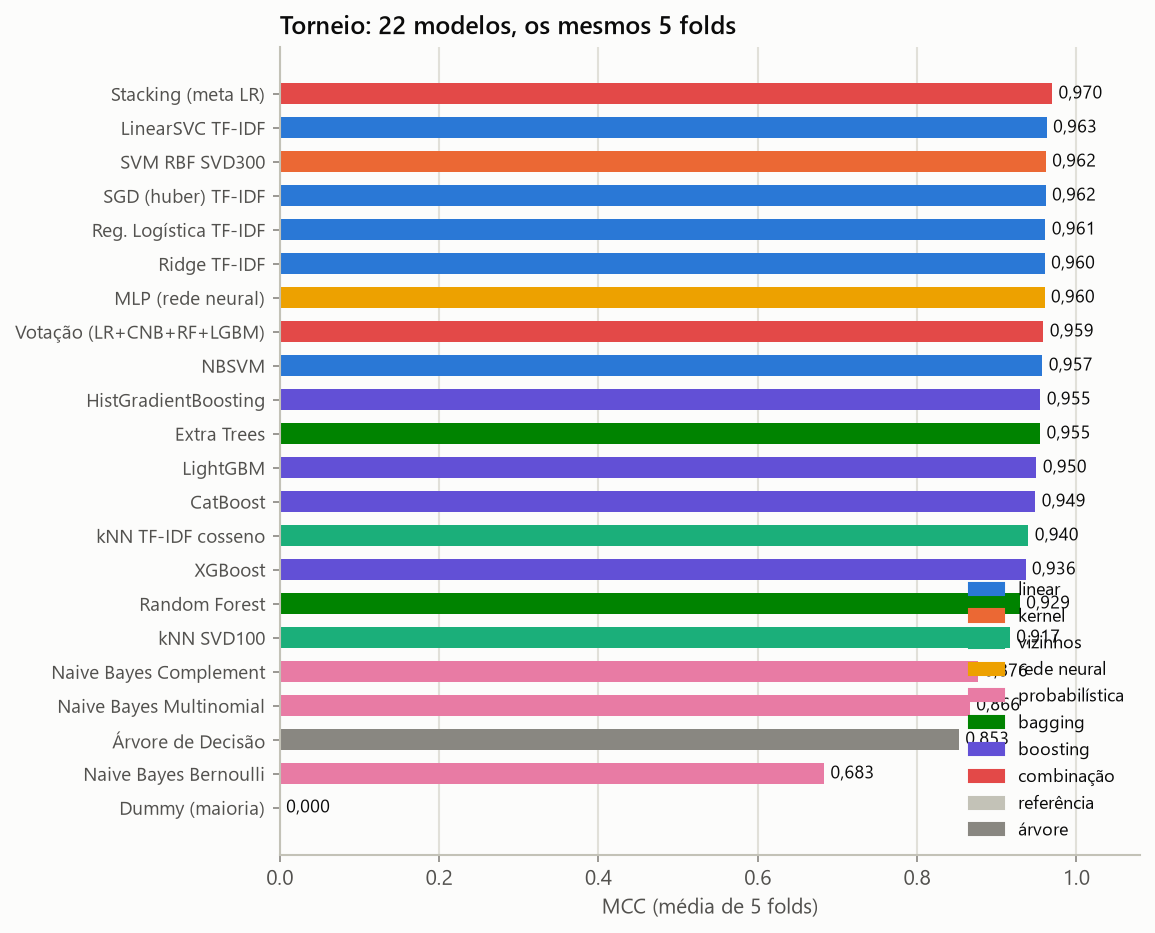

O detalhe que virou o jogo, TF-IDF com log: Reg. Logística 0,923 → 0,961; kNN 0,746 → 0,940


In [8]:
fig_("03_torneio")
a = R["achados"]
print(f"O detalhe que virou o jogo, TF-IDF com log: Reg. Logística {num(a['lr_mcc_antes'])} → {num(a['lr_mcc_depois'])}; "
      f"kNN {num(a['knn_mcc_antes'])} → {num(a['knn_mcc_depois'])}")

## 6. Ninguém vence sozinho: o Stacking 7
Um modelo de cada família; um meta-modelo aprende quanto confiar em cada um. As notas que alimentam o
meta-modelo são *out-of-fold* (nenhum modelo dá nota a um e-mail que usou para treinar). O motor guarda essas
notas em cache, e por isso dá para recalcular os 20 folds de confirmação aqui, em segundos:

                                 mcc_custo  pr_auc  custo_por_mil
metodo                                                           
LinearSVC (melhor modelo único)     0.9392  0.9952        52.0293
Stacking 7 padrão                   0.9554  0.9973        41.5130
MCC (limiar 0,5): Stacking 7 − LinearSVC otimizado = +0,0107, p de Holm 0,042 (significativo a 5%)
custo: Stacking 7 padrão × LinearSVC = -10,5 por mil (20,2% menos; IC95 -26,4 a +5,4; p de Holm 0,728; P(mais barato) 0,83)
custo: Especialista (S7 do GA) × LinearSVC = -15,4 por mil (29,6% menos; IC95 -30,1 a -0,7; p de Holm 0,246; P(mais barato) 0,95)


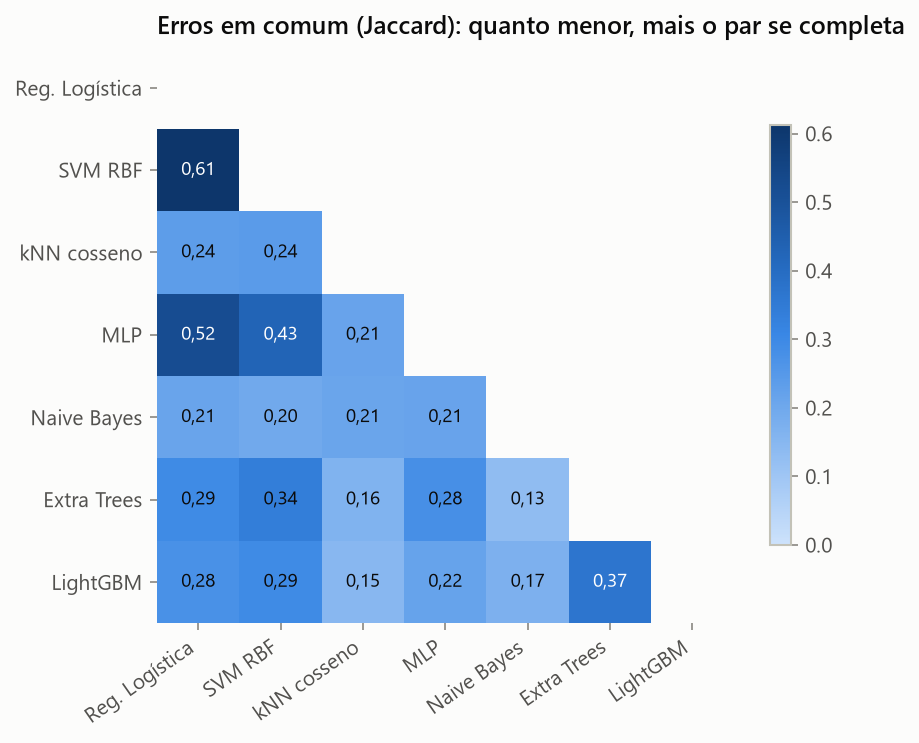

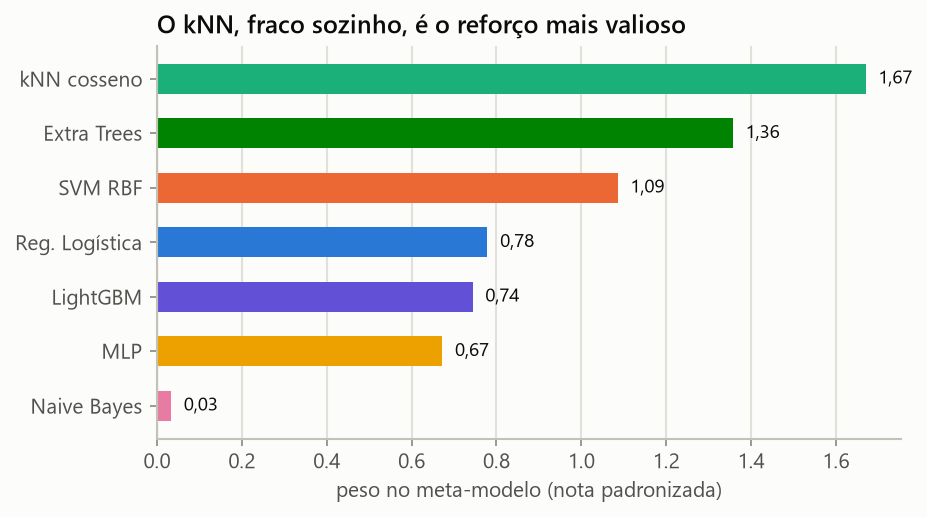

quanto cada um erra junto com os outros (Jaccard médio dos erros; menor = mais diferente): Naive Bayes 0,19, kNN cosseno 0,20, LightGBM 0,25, Extra Trees 0,26, MLP 0,31, SVM RBF 0,35, Reg. Logística 0,36
peso no meta-modelo: kNN cosseno 1,67, Extra Trees 1,36, SVM RBF 1,09, Reg. Logística 0,78, LightGBM 0,74, MLP 0,67, Naive Bayes 0,03
Stacking 7 × Stacking 13: P(equivalentes) = 0,999


In [9]:
m = Motor(base, log=lambda *a: None)
CONF = m.adicionar_divisoes([201, 202, 203, 204])
linhas = []
for c in CONF:
    yte = m.y_teste(c)
    linhas.append(dict(metodo="Stacking 7 padrão", **metricas.metricas(yte, *m.prever_stacking(modelos.STACKING7_PADRAO, c))))
    linhas.append(dict(metodo="LinearSVC (melhor modelo único)", **metricas.metricas(yte, *m.prever_linearsvc(0, c))))
T = pd.DataFrame(linhas).groupby("metodo")[["mcc_custo", "pr_auc", "custo_por_mil"]].mean()
print(T.round(4).to_string())
mm = next(r for r in R["genetico"]["comparacoes"] if r["A"] == "Stacking 7 padrão" and r["B"] == "LinearSVC otimizado")
print(f"MCC (limiar 0,5): Stacking 7 − LinearSVC otimizado = {sn(mm['dif'])}, p de Holm {num(mm['p_holm'])} "
      f"({'significativo' if mm['p_holm'] < 0.05 else 'não significativo'} a 5%)")
cmp = {(r["A"], r["B"]): r for r in R["comparacoes_custo_20_folds"]}
for k in ["generalista_sem_chave", "especialista"]:
    r = cmp[(k, "linha_de_base")]
    print(f"custo: {F[k]['rotulo']} × LinearSVC = {sn(r['dif'], 1)} por mil ({pct(r['reducao_relativa'])} menos; IC95 "
          f"{sn(r['ic95_lo'], 1)} a {sn(r['ic95_hi'], 1)}; p de Holm {num(r['p_holm'])}; P(mais barato) {num(r['P_A_melhor'], 2)})")
fig_("04_erros_em_comum"); fig_("04_pesos_meta")
ec = R["stacking"]["erros_em_comum"]; M = np.array(ec["matriz"]); np.fill_diagonal(M, np.nan)
juntos = pd.Series(np.nanmean(M, 1), index=ec["modelos"]).sort_values()
print("quanto cada um erra junto com os outros (Jaccard médio dos erros; menor = mais diferente):",
      ", ".join(f"{k} {num(v, 2)}" for k, v in juntos.items()))
print("peso no meta-modelo:", ", ".join(f"{k} {num(v, 2)}" for k, v in sorted(R["stacking"]["pesos_meta"].items(), key=lambda x: -x[1])))
eq13 = next(c for c in R["stacking"]["comparacoes_15_folds"] if c["B"] == "Stacking 13 (todos)")
print(f"Stacking 7 × Stacking 13: P(equivalentes) = {num(eq13['P_equivalentes'])}")

O kNN e o Naive Bayes são os que menos erram junto com os outros, e o meta-modelo dá ao kNN o maior peso (os
pesos dividem crédito entre membros correlacionados, então não são uma medida pura de confiança). Treze modelos
empatam com sete. Contra o melhor modelo único, o stacking ganha no MCC e custa menos em média; a saída acima diz
quais dessas diferenças são estatisticamente significativas com estes e-mails.

## 7. O algoritmo genético e a maldição do vencedor
O espaço de hiperparâmetros tem milhões de combinações (saída abaixo). Com o cache, cada avaliação é só o
meta-modelo: o GA inteiro roda aqui em cerca de um minuto e meio.

857 avaliações, de 7.077.888 combinações possíveis
MCC na busca: padrão 0,9732 → GA 0,9795 (ganho +0,0063)
em 20 divisões de confirmação: ganho +0,0010 (IC95 corrigido -0,0049 a +0,0068)


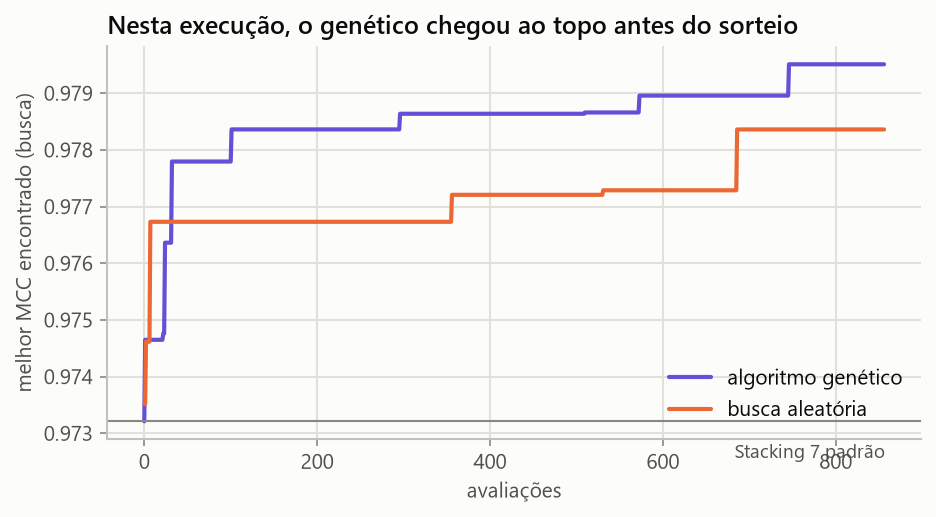

In [10]:
BUSCA = m.adicionar_divisoes([11, 12], prefixo="b")
apt = genetico.Aptidao(m, BUSCA)
melhor, hist = genetico.algoritmo_genetico(apt)
g = R["genetico"]
print(f"{len(apt.memoria)} avaliações, de {g['combinacoes']:,} combinações possíveis".replace(",", "X").replace("X de", ", de").replace("X", "."))
print(f"MCC na busca: padrão {num(apt(modelos.STACKING7_PADRAO), 4)} → GA {num(apt(melhor), 4)} (ganho {sn(g['ganho_busca'])})")
lo, hi = g["ganho_sementes_novas_ic95"]
print(f"em 20 divisões de confirmação: ganho {sn(g['ganho_sementes_novas'])} (IC95 corrigido {sn(lo)} a {sn(hi)})")
fig_("05_ga_x_aleatoria")

Na busca, o GA melhora o MCC. Nas divisões de confirmação, o ganho encolhe e o intervalo de confiança inclui o
zero: **o ganho não se confirmou**. O encolhimento é o efeito esperado de escolher o melhor entre centenas de
candidatos nas mesmas divisões (a "maldição do vencedor"), mas o intervalo é largo demais para dizer quanto do
ganho era otimismo. A configuração do GA virou o **Especialista**: é o filtro de menor custo nestas divisões, que
são re-partições dos e-mails usados na escolha.

## 8. O modelo de fundação: TabPFN
O TabPFN-3.5 (Prior Labs) foi pré-treinado em milhões de tabelas sintéticas e classifica uma tabela nova **sem
nenhum ajuste**. Ele entra de duas formas: sozinho e como 8º membro do stacking (**Stacking 8**).

nesta caixa, 20 folds: TabPFN sozinho MCC 0,962 × LinearSVC otimizado 0,963 (afinado) | PR-AUC: Stacking 8 0,9978, Stacking 7 0,9973
fora da caixa (Enron2-6), custo por mil: TabPFN sozinho 126,0 | Stacking 8 138,5 | Stacking 7 177,5 | LinearSVC 156,9
e-mails reais na lixeira no Enron2-6: TabPFN 0,9% × Stacking 7 3,2%


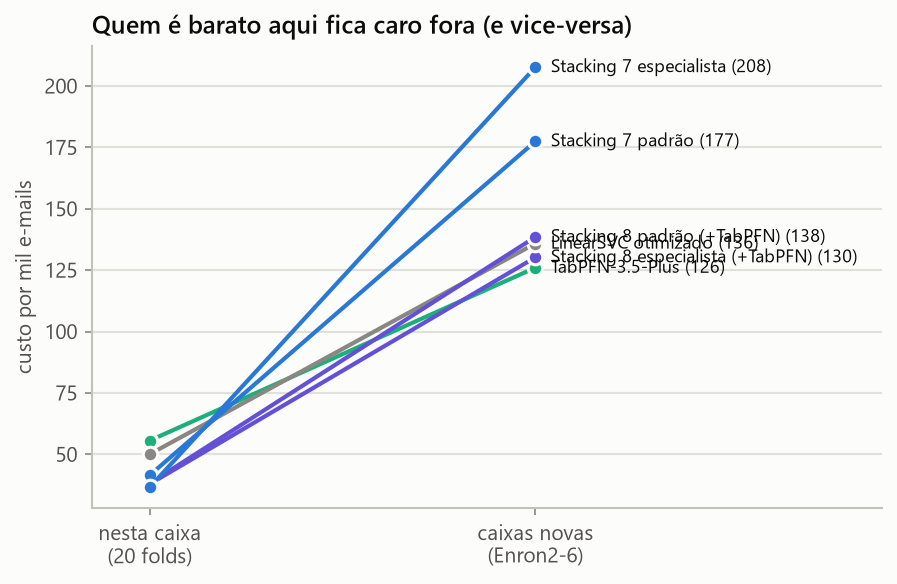

In [11]:
tab = {r["metodo"]: r for r in R["tabpfn"]["interno"]}
print(f"nesta caixa, 20 folds: TabPFN sozinho MCC {num(tab['TabPFN-3.5-Plus']['mcc'])} × LinearSVC otimizado "
      f"{num(tab['LinearSVC otimizado']['mcc'])} (afinado) | PR-AUC: Stacking 8 {num(F['generalista']['cv20']['pr_auc'], 4)}, "
      f"Stacking 7 {num(F['generalista_sem_chave']['cv20']['pr_auc'], 4)}")
print(f"fora da caixa (Enron2-6), custo por mil: TabPFN sozinho {num(F['tabpfn']['externo']['custo_por_mil'], 1)} | "
      f"Stacking 8 {num(F['generalista']['externo']['custo_por_mil'], 1)} | Stacking 7 {num(F['generalista_sem_chave']['externo']['custo_por_mil'], 1)} | "
      f"LinearSVC {num(F['linha_de_base']['externo']['custo_por_mil'], 1)}")
print(f"e-mails reais na lixeira no Enron2-6: TabPFN {pct(F['tabpfn']['externo']['real_lixeira_custo'])} × "
      f"Stacking 7 {pct(F['generalista_sem_chave']['externo']['real_lixeira_custo'])}")
fig_("06_custo_dentro_fora")

Sem nenhum ajuste, o TabPFN empata com o melhor modelo único afinado nesta caixa. Fora dela, é o mais conservador:
o que menos manda e-mail real para a lixeira. Por isso é o mais barato onde predominam e-mails reais e na média do
Enron2-6, e caro onde predomina spam. Como 8º membro, deixa o stacking bem mais barato fora da caixa.

## 9. A grande final: três avaliações, uma regra escrita antes
A base externa (Enron2-6) sugeriu que o Stacking 8 generaliza melhor que o Stacking 7. Para decidir sem viés, a
regra foi registrada **antes** de rodar numa terceira base que nenhuma escolha tinha usado (SpamAssassin):

SpamAssassin: 6046 mensagens. Stacking 8 − Stacking 7: -857 por mil (P(redução) = 1,000); MCC no limiar de custo +0,022
decisão (D10): o Stacking 8 substitui o Stacking 7 como stacking para caixas novas


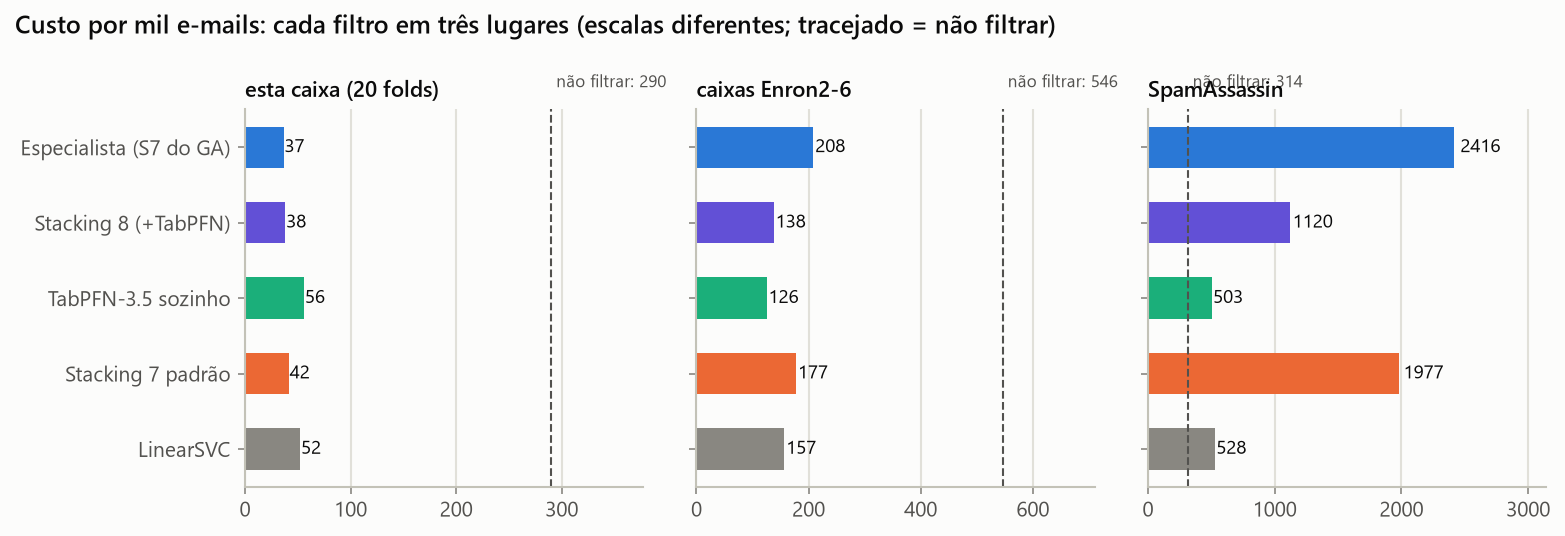

                         MCC (limiar de custo, 20 folds)  PR-AUC (20 folds)  custo/mil (20 folds)  Enron2-6  SpamAssassin  TCR SpamAssassin
Especialista (S7 do GA)                            0.962              0.998                36.618   207.650      2416.474             0.130
Stacking 8 (+TabPFN)                               0.956              0.998                38.192   138.496      1119.914             0.280
TabPFN-3.5 sozinho                                 0.922              0.997                55.594   125.995       503.473             0.623
Stacking 7 padrão                                  0.955              0.997                41.513   177.453      1977.175             0.159
LinearSVC                                          0.939              0.995                52.029   156.939       528.449             0.593
não filtrar                                        0.000              0.290               290.065   546.395       313.596             1.000
Enron2-6: não filtra

In [12]:
tb = R["terceira_base"]; dcs = tb["decisao"]
print(f"SpamAssassin: {tb['n']} mensagens. Stacking 8 − Stacking 7: {sn(dcs['diferenca_custo'], 0)} por mil "
      f"(P(redução) = {num(dcs['p_reducao'])}); MCC no limiar de custo {sn(dcs['diferenca_mcc_custo'], 3)}")
print("decisão (D10):", "o Stacking 8 substitui o Stacking 7 como stacking para caixas novas" if dcs["stacking8_vira_generalista"]
      else "o Stacking 7 continua")
fig_("09_filtros_finais")
tab = pd.DataFrame({F[n]["rotulo"]: {"MCC (limiar de custo, 20 folds)": F[n]["cv20"]["mcc_custo"], "PR-AUC (20 folds)": F[n]["cv20"]["pr_auc"],
                                    "custo/mil (20 folds)": F[n]["cv20"]["custo_por_mil"],
                                    "Enron2-6": F[n]["externo"]["custo_por_mil"], "SpamAssassin": F[n]["spamassassin"]["custo_por_mil"],
                                    "TCR SpamAssassin": F[n]["spamassassin"]["tcr"]} for n in F}).T
print(tab.round(3).to_string())
for onde, chave in [("Enron2-6", "externo"), ("SpamAssassin", "spamassassin")]:
    ref = F["nao_filtrar"][chave]["custo_por_mil"]
    vence = [F[n]["rotulo"] for n in F if n != "nao_filtrar" and F[n][chave]["custo_por_mil"] < ref]
    print(f"{onde}: não filtrar custa {num(ref, 1)}; mais baratos que isso: {', '.join(vence) or 'nenhum filtro'}")

**Leitura.** Nesta caixa, o Especialista é o mais barato nos 20 folds (no teste trancado, empata com o padrão), e o
Stacking 8 empata no topo do PR-AUC. Nas cinco
caixas Enron2-6 somadas, todos os filtros valem a pena, e o TabPFN e o Stacking 8 são os que mais economizam;
caixa a caixa, nas que têm maioria de e-mails reais (como o Enron2), os stackings chegam a perder para não
filtrar. No
SpamAssassin, com λ = 9, nenhum filtro treinado no Enron1 vence "não filtrar": o TabPFN sozinho chega mais perto, e
o TabPFN também deixa os dois stackings bem mais baratos (a regra D10 trocou o Stacking 7 padrão pelo Stacking 8). **Para uma caixa muito diferente, o caminho é retreinar.**

## 10. Contra-estudo: tentando derrubar as conclusões

teste de sinal: com os rótulos embaralhados 999 vezes, o MCC vai de 0,961 para +0,001 em média (máximo +0,050); p = 0,001, o menor possível. O MCC não vem do acaso.
quase-cópias (cosseno ≥ 0,95): 13,9% dos e-mails de teste nos 20 folds; sem elas, o MCC do Stacking 7 vai de 0,9734 para 0,9703
                                  mcc_esta_caixa  mcc_enron2_6  pr_auc_enron2_6  mcc_spamassassin  pr_auc_spamassassin
variante                                                                                                              
todas as 3000 colunas                      0.961         0.853            0.989             0.411                0.796
sem as 35 palavras da Enron                0.959         0.847            0.987             0.460                0.799
sem as da Enron e sem 1-2 letras           0.953         0.832            0.984             0.478                0.773


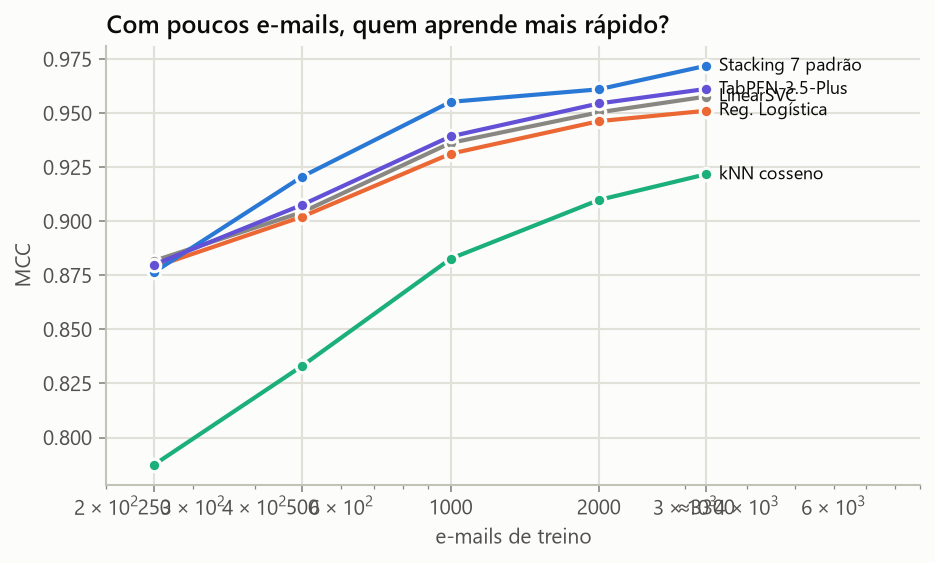

mais barato para cada λ:
                 onde  custo_fp                  metodo  custo_por_mil
             Enron2-6         1 Stacking 7 especialista           43.1
             Enron2-6         3 TabPFN-3.5-Plus sozinho           77.0
             Enron2-6         9 TabPFN-3.5-Plus sozinho          126.0
             Enron2-6        20 TabPFN-3.5-Plus sozinho          159.2
esta caixa (20 folds)         1 Stacking 7 especialista           10.5
esta caixa (20 folds)         3 Stacking 7 especialista           19.2
esta caixa (20 folds)         9 Stacking 7 especialista           36.6
esta caixa (20 folds)        20 Stacking 7 especialista           57.8
controle da 3ª base: treinado e testado dentro do SpamAssassin, MCC 0,968: a representação funciona lá. Conversor no spam: a decisão quase não muda (0,8% × 0,9% de spam que passou).
  base  email_real                    spam
Enron1    farmer-d                      GP
Enron2  kaminski-v SpamAssassin + HoneyPot
Enron3   kitchen-l       

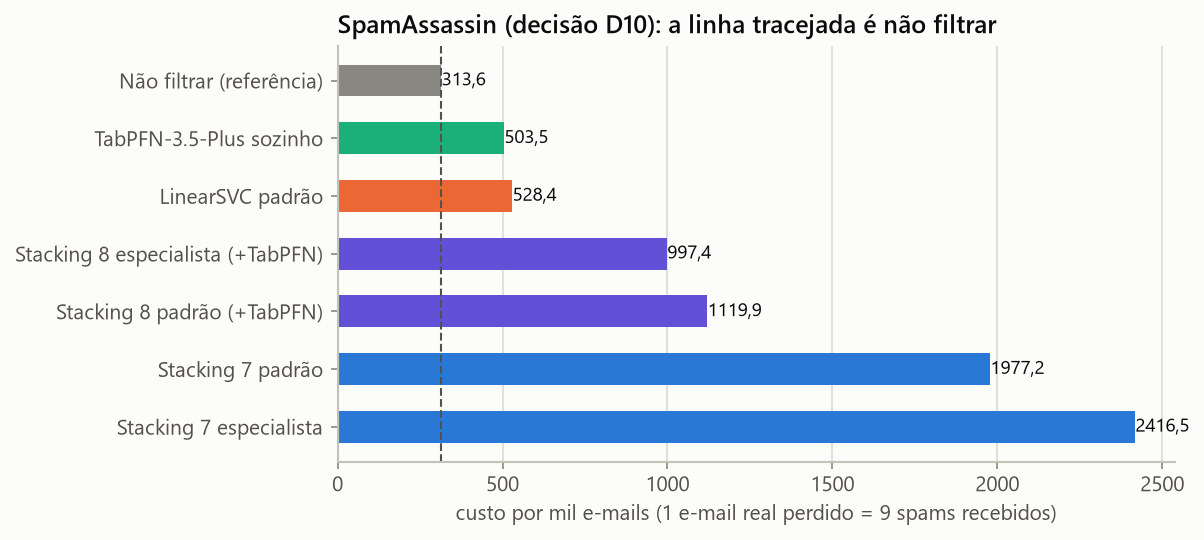

In [13]:
ce = R["contra_estudo"]; pm = ce["permutacao"]
print(f"teste de sinal: com os rótulos embaralhados {pm['n_permutacoes']} vezes, o MCC vai de {num(pm['mcc_real'])} para "
      f"{sn(pm['mcc_permutado_media'], 3)} em média (máximo {sn(pm['mcc_permutado_max'], 3)}); p = {num(pm['p'])}, o menor possível. "
      f"O MCC não vem do acaso.")
q = ce["quase_copias"]
print(f"quase-cópias (cosseno ≥ {num(q['limiar_cosseno'], 2)}): {pct(q['folds_fracao'])} dos e-mails de teste nos 20 folds; "
      f"sem elas, o MCC do Stacking 7 vai de {num(q['mcc'], 4)} para {num(q['mcc_sem_quase_copias'], 4)}")
print(pd.DataFrame(ce["ablacao"]).set_index("variante").round(3).to_string())
fig_("07_curva_aprendizado")
venc = pd.DataFrame(ce["vencedor_por_custo"])
print("mais barato para cada λ:\n" + venc.round(1).to_string(index=False))
cv = tb["conversor_spam"]
print(f"controle da 3ª base: treinado e testado dentro do SpamAssassin, MCC {num(tb['controle_dentro_da_base']['mcc'])}: "
      f"a representação funciona lá. Conversor no spam: a decisão quase não muda ({pct(cv['enron4_spam_passou_aueb'])} × "
      f"{pct(cv['enron4_spam_passou_conversor'])} de spam que passou).")
print(pd.DataFrame(tb["fontes_spam"])[["base", "email_real", "spam"]].to_string(index=False))
fig_("08_terceira_base")

O teste de permutação mostra que há sinal; a proteção contra vazamento é o agrupamento das cópias, e as
quase-cópias inflam pouco o resultado. O spam de cada caixa vem de uma coleção: caixas com a mesma coleção não são
independentes no spam, e o spam do SpamAssassin é parente do spam do Enron2 e do Enron5. Fora da caixa, o stacking
erra mais nos e-mails reais e no spam: ele aprende o que é "normal" na caixa do treino e na coleção de spam dela.

## 11. A demonstração: um e-mail, todas as etapas
O filtro treinado fica na página *Releases* do GitHub; se não estiver em `resultados/modelos/`, é baixado aqui.

In [14]:
from spamfilter.filtro import FiltroStacking
esp = FiltroStacking.carregar(publicados.garantir("especialista"))
for ex in R["exemplos_demo"]:
    e = esp.explicar(ex["texto"])
    print(f"{ex['rotulo']:24s} cobertura {pct(e['cobertura'])} | P(spam) {pct(e['prob_spam'])} | limiar {pct(e['limiar'])} | "
          f"{'SPAM' if e['spam'] else 'e-mail real'}")

spam                     cobertura 82,6% | P(spam) 98,7% | limiar 71,1% | SPAM
e-mail real              cobertura 81,0% | P(spam) 0,1% | limiar 71,1% | e-mail real


e-mail real (português)  cobertura 16,2% | P(spam) 99,7% | limiar 71,1% | SPAM


O exemplo em português é um e-mail real, mas o filtro, treinado em inglês, o manda para a lixeira: com cobertura
baixa, a decisão não tem sentido.

## 12. Conclusões
1. **Conhecer os dados mudou tudo:** a base é o Enron1, a contagem é por substring e as duplicatas são e-mails
   reais; o protocolo separa cópias por grupo.
2. **A representação vale mais que o algoritmo:** TF-IDF com log levou modelos simples ao topo.
3. **Modelos que erram diferente se completam:** um modelo de cada família, combinados por um meta-modelo,
   superam o melhor modelo único no MCC e custam menos em média; treze modelos não superam sete.
4. **O ajuste fino rende pouco:** o ganho do algoritmo genético não se confirmou em divisões novas, e há um piso
   estatístico abaixo do qual nenhuma diferença é detectável com estes e-mails.
5. **O TabPFN é a surpresa:** sem nenhum ajuste, empata com o melhor modelo único afinado; fora da caixa, é o
   mais conservador com e-mails reais e deixa o stacking bem mais barato.
6. **O stacking aprende a caixa:** fora dela, tudo piora. Numa caixa muito diferente, com λ = 9, nenhum filtro
   treinado aqui vence não filtrar; o caminho é retreinar com e-mails da caixa de destino.

**Filtros:** entregues prontos para uso, o Especialista (Stacking 7 do GA), o Stacking 7 padrão (roda sem chave, usado
na demo) e o LinearSVC (linha de base); avaliados com as notas gravadas do TabPFN, o Stacking 8 e o TabPFN sozinho. Detalhes, decisões e números: `docs/REGISTRO_DECISOES.md`.